In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df=pd.read_csv('../dataset/olist_order_items_dataset.csv')
df.head(2)

,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value
0,00010242fe8c5a6d1ba2dd792cb16214,1,4244733e06e7ecb4970a6e2683c13e61,48436dade18ac8b2bce089ec2a041202,2017-09-19 09:45:35,58.9,13.29
1,00018f77f2f0320c557190d7a144bdd3,1,e5f2d52b802189ee658865ca93d83a8f,dd7ddc04e1b6c2c614352b383efe2d36,2017-05-03 11:05:13,239.9,19.93


In [3]:
df.shape

(112650, 7)

In [4]:
s_df=pd.read_csv('../dataset/olist_sellers_dataset.csv')
p_df=pd.read_csv('../dataset/olist_products_dataset.csv')
o_df=pd.read_csv('../dataset/olist_orders_dataset.csv')
c_df=pd.read_csv('../dataset/olist_customers_dataset.csv')
g_df=pd.read_csv('../dataset/olist_geolocation_dataset.csv')

In [5]:
g_df = g_df.drop_duplicates(subset=['geolocation_zip_code_prefix'])

In [6]:
df.columns

Index(['order_id', 'order_item_id', 'product_id', 'seller_id',
       'shipping_limit_date', 'price', 'freight_value'],
      dtype='object')

In [7]:
g_df.columns

Index(['geolocation_zip_code_prefix', 'geolocation_lat', 'geolocation_lng',
       'geolocation_city', 'geolocation_state'],
      dtype='object')

In [8]:
s_df=s_df.merge(g_df[['geolocation_zip_code_prefix','geolocation_lat','geolocation_lng']],left_on='seller_zip_code_prefix',right_on='geolocation_zip_code_prefix',how='left')

In [9]:
s_df=s_df.rename(columns={
    'geolocation_lat':'seller_lat',
    'geolocation_lng':'seller_lng'
})
s_df.head(2)

,seller_id,seller_zip_code_prefix,seller_city,seller_state,geolocation_zip_code_prefix,seller_lat,seller_lng
0,3442f8959a84dea7ee197c632cb2df15,13023,campinas,SP,13023.0,-22.898536,-47.063125
1,d1b65fc7debc3361ea86b5f14c68d2e2,13844,mogi guacu,SP,13844.0,-22.382941,-46.946641


In [10]:
s_df.shape

(3095, 7)

In [11]:
df=df.merge(s_df[['seller_id','seller_state','seller_lat','seller_lng']],on='seller_id',how='left')
df.head(3)

,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value,seller_state,seller_lat,seller_lng
0,00010242fe8c5a6d1ba2dd792cb16214,1,4244733e06e7ecb4970a6e2683c13e61,48436dade18ac8b2bce089ec2a041202,2017-09-19 09:45:35,58.9,13.29,SP,-22.498183,-44.123614
1,00018f77f2f0320c557190d7a144bdd3,1,e5f2d52b802189ee658865ca93d83a8f,dd7ddc04e1b6c2c614352b383efe2d36,2017-05-03 11:05:13,239.9,19.93,SP,-23.566258,-46.518417
2,000229ec398224ef6ca0657da4fc703e,1,c777355d18b72b67abbeef9df44fd0fd,5b51032eddd242adc84c38acab88f23d,2018-01-18 14:48:30,199.0,17.87,MG,-22.264094,-46.158564


In [12]:
c_df=c_df.merge(g_df[['geolocation_zip_code_prefix','geolocation_lat','geolocation_lng']],left_on='customer_zip_code_prefix',right_on='geolocation_zip_code_prefix',how='left')

In [13]:
c_df=c_df.rename(columns={
    'geolocation_lat':'customer_lat',
    'geolocation_lng':'customer_lng'
})
c_df.head(2)

,customer_id,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state,geolocation_zip_code_prefix,customer_lat,customer_lng
0,06b8999e2fba1a1fbc88172c00ba8bc7,861eff4711a542e4b93843c6dd7febb0,14409,franca,SP,14409.0,-20.509897,-47.397866
1,18955e83d337fd6b2def6b18a428ac77,290c77bc529b7ac935b93aa66c333dc3,9790,sao bernardo do campo,SP,9790.0,-23.726853,-46.545746


In [14]:
c_df.shape

(99441, 8)

In [15]:
c_df=c_df.drop_duplicates()

In [16]:
c_df_unique = c_df.drop_duplicates(subset=['customer_id'])

o_df = o_df.merge(c_df_unique[['customer_id','customer_state','customer_lat','customer_lng']],on='customer_id',how='left')

In [17]:
o_df.shape

(99441, 11)

In [18]:
o_df=o_df.drop_duplicates()

In [19]:
df=df.merge(o_df[['order_id','customer_state','customer_lat','customer_lng']],on='order_id',how='left')

In [20]:
df.columns

Index(['order_id', 'order_item_id', 'product_id', 'seller_id',
       'shipping_limit_date', 'price', 'freight_value', 'seller_state',
       'seller_lat', 'seller_lng', 'customer_state', 'customer_lat',
       'customer_lng'],
      dtype='object')

In [21]:
df.shape

(112650, 13)

In [22]:
df=df.merge(p_df[['product_id', 'product_weight_g','product_length_cm','product_height_cm','product_width_cm']],on='product_id',how='left')

In [23]:
df.columns

Index(['order_id', 'order_item_id', 'product_id', 'seller_id',
       'shipping_limit_date', 'price', 'freight_value', 'seller_state',
       'seller_lat', 'seller_lng', 'customer_state', 'customer_lat',
       'customer_lng', 'product_weight_g', 'product_length_cm',
       'product_height_cm', 'product_width_cm'],
      dtype='object')

In [24]:
df.isnull().sum()

order_id                 0
order_item_id            0
product_id               0
seller_id                0
shipping_limit_date      0
price                    0
freight_value            0
seller_state             0
seller_lat             253
seller_lng             253
customer_state           0
customer_lat           302
customer_lng           302
product_weight_g        18
product_length_cm       18
product_height_cm       18
product_width_cm        18
dtype: int64

In [25]:
df.shape

(112650, 17)

In [26]:
df=df.dropna()

In [27]:
df.head(5)

,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value,seller_state,seller_lat,seller_lng,customer_state,customer_lat,customer_lng,product_weight_g,product_length_cm,product_height_cm,product_width_cm
0,00010242fe8c5a6d1ba2dd792cb16214,1,4244733e06e7ecb4970a6e2683c13e61,48436dade18ac8b2bce089ec2a041202,2017-09-19 09:45:35,58.90,13.29,SP,-22.498183,-44.123614,RJ,-21.758076,-41.312633,650.0,28.0,9.0,14.0
1,00018f77f2f0320c557190d7a144bdd3,1,e5f2d52b802189ee658865ca93d83a8f,dd7ddc04e1b6c2c614352b383efe2d36,2017-05-03 11:05:13,239.90,19.93,SP,-23.566258,-46.518417,SP,-20.212393,-50.941471,30000.0,50.0,30.0,40.0
2,000229ec398224ef6ca0657da4fc703e,1,c777355d18b72b67abbeef9df44fd0fd,5b51032eddd242adc84c38acab88f23d,2018-01-18 14:48:30,199.00,17.87,MG,-22.264094,-46.158564,MG,-19.860439,-44.597972,3050.0,33.0,13.0,33.0
3,00024acbcdf0a6daa1e931b038114c75,1,7634da152a4610f1595efa32f14722fc,9d7a1d34a5052409006425275ba1c2b4,2018-08-15 10:10:18,12.99,12.79,SP,-20.548228,-47.395897,SP,-23.144923,-46.539830,200.0,16.0,10.0,15.0
4,00042b26cf59d7ce69dfabb4e55b4fd9,1,ac6c3623068f30de03045865e4e10089,df560393f3a51e74553ab94004ba5c87,2017-02-13 13:57:51,199.90,18.14,PR,-22.931427,-53.133759,SP,-23.249008,-46.824961,3750.0,35.0,40.0,30.0


In [28]:
df['volume_cm3']=df['product_length_cm']*df['product_height_cm']*df['product_width_cm']

In [29]:
df=df.drop(columns=['order_id','order_item_id','product_id','seller_id','shipping_limit_date','product_length_cm','product_height_cm','product_width_cm'])
df.columns

Index(['price', 'freight_value', 'seller_state', 'seller_lat', 'seller_lng',
       'customer_state', 'customer_lat', 'customer_lng', 'product_weight_g',
       'volume_cm3'],
      dtype='object')

In [30]:
def haversine(lat1, lon1, lat2, lon2):
    lat1, lon1, lat2, lon2 = map(np.radians, [lat1, lon1, lat2, lon2])
    dlat = lat2 - lat1
    dlon = lon2 - lon1
    a = np.sin(dlat/2)**2 + np.cos(lat1)*np.cos(lat2)*np.sin(dlon/2)**2
    c = 2*np.arcsin(np.sqrt(a))
    R = 6371
    return R * c

In [31]:
df['distance_km'] = haversine(df['seller_lat'], df['seller_lng'],df['customer_lat'], df['customer_lng'])

In [32]:
df.head(2)

,price,freight_value,seller_state,seller_lat,seller_lng,customer_state,customer_lat,customer_lng,product_weight_g,volume_cm3,distance_km
0,58.9,13.29,SP,-22.498183,-44.123614,RJ,-21.758076,-41.312633,650.0,3528.0,301.005664
1,239.9,19.93,SP,-23.566258,-46.518417,SP,-20.212393,-50.941471,30000.0,60000.0,589.274140


In [33]:
df=df[['seller_state','customer_state','distance_km','product_weight_g','volume_cm3','price','freight_value']]
df.head(2)

,seller_state,customer_state,distance_km,product_weight_g,volume_cm3,price,freight_value
0,SP,RJ,301.005664,650.0,3528.0,58.9,13.29
1,SP,SP,589.274140,30000.0,60000.0,239.9,19.93


In [34]:
df.duplicated().sum()

np.int64(10794)

In [35]:
df=df.drop_duplicates()

In [36]:
num_cols=df.dtypes[df.dtypes!='object'].index
cat_cols=df.dtypes[df.dtypes=='object'].index

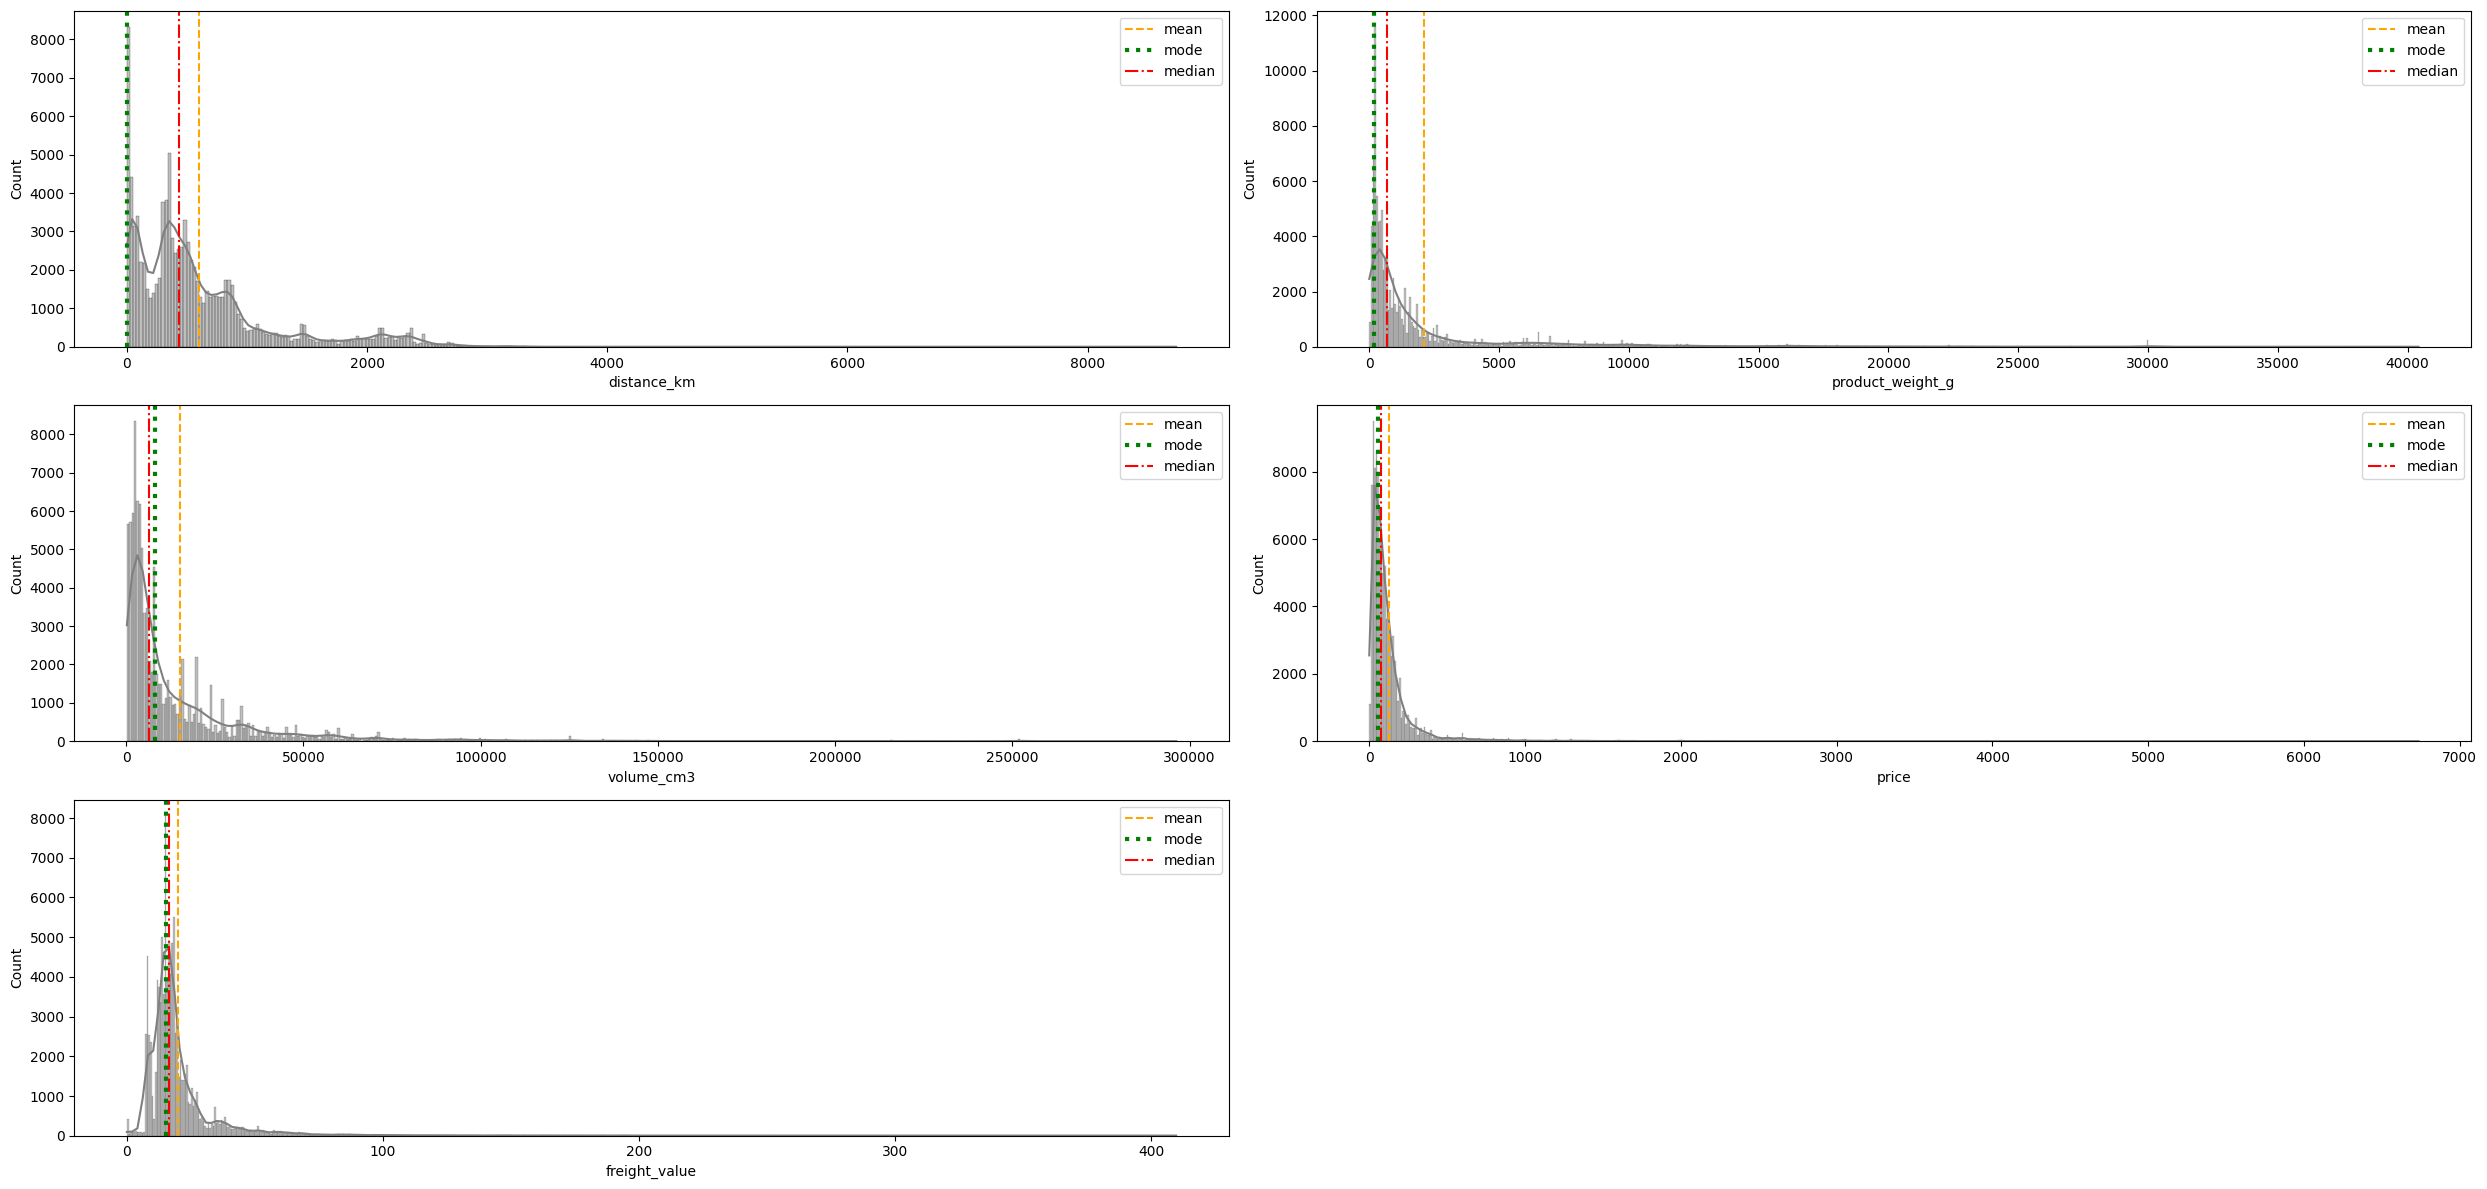

In [37]:
cols=num_cols
plt.figure(figsize=(25,12))
for i in range(len(num_cols)):
    plt.subplot(len(num_cols)//2+1,2,i+1)
    sns.histplot(data=df,x=df[cols[i]],kde=True,color='grey')
    plt.axvline(df[cols[i]].mean(),color='orange',linestyle="--",label='mean')
    plt.axvline(df[cols[i]].mode()[0],color='green',linestyle=":",linewidth=3,label='mode')
    plt.axvline(df[cols[i]].median(),color='red',linestyle="-.",label='median')
    plt.legend()

plt.tight_layout()
plt.show()

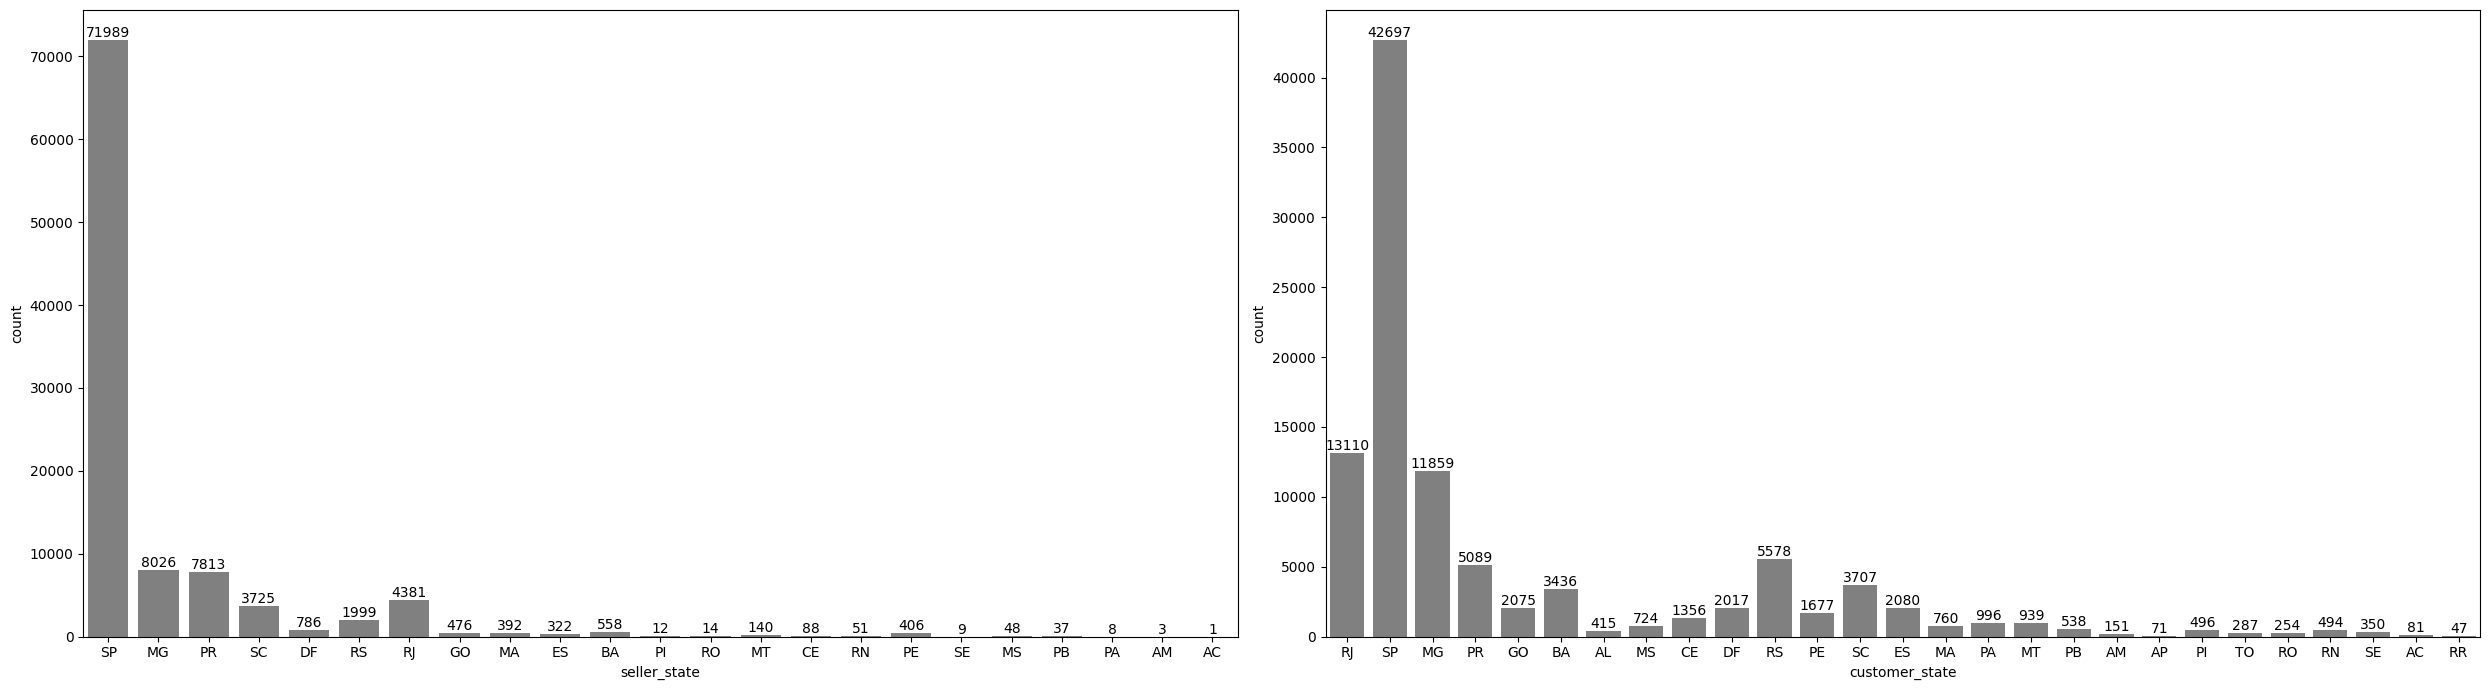

In [38]:
cols=cat_cols
plt.figure(figsize=(25,7))
for i in range(len(cat_cols)):
    plt.subplot(1,2,i+1)
    ax=sns.countplot(data=df,x=df[cols[i]],color='grey')
    plt.bar_label(ax.containers[0])
plt.tight_layout()
plt.show()

In [39]:
df['seller_state'].value_counts()

seller_state
SP    71989
MG     8026
PR     7813
RJ     4381
SC     3725
RS     1999
DF      786
BA      558
GO      476
PE      406
MA      392
ES      322
MT      140
CE       88
RN       51
MS       48
PB       37
RO       14
PI       12
SE        9
PA        8
AM        3
AC        1
Name: count, dtype: int64

In [40]:
r=['SE','PA','AM','AC']
df = df[~df['seller_state'].isin(r)]

In [41]:
x1=df[num_cols].describe(percentiles=[0.01,0.02,0.05,0.5,0.93,0.94,0.95,0.98,0.99]).T
x1=x1.iloc[:,3:]
x1

,min,1%,2%,5%,50%,93%,94%,95%,98%,99%,max
distance_km,0.00,5.818624,8.818405,16.588932,433.541365,1851.884667,1980.328987,2096.650357,2359.360433,2482.100099,8736.947618
product_weight_g,0.00,75.000000,100.000000,125.000000,700.000000,7850.000000,8800.000000,9750.000000,15350.000000,18250.000000,40425.000000
volume_cm3,168.00,352.000000,561.000000,816.000000,6384.000000,48026.000000,52650.000000,57200.000000,89657.600000,113100.000000,296208.000000
price,0.85,10.990000,12.990000,18.000000,78.900000,299.000000,329.000000,359.990000,649.170000,899.000000,6735.000000
freight_value,0.00,5.120000,7.390000,7.780000,16.330000,39.220000,42.510000,45.650000,65.705200,85.296600,409.680000


In [42]:
# df=df[df['product_weight_g']<df['product_weight_g'].quantile(0.99)]

In [44]:
x1=df[num_cols].describe(percentiles=[0.01,0.02,0.05,0.5,0.95,0.98,0.99]).T
x1=x1.iloc[:,3:]
x1

,min,1%,2%,5%,50%,95%,98%,99%,max
distance_km,0.00,5.818624,8.818405,16.588932,433.541365,2096.650357,2359.360433,2482.100099,8736.947618
product_weight_g,0.00,75.000000,100.000000,125.000000,700.000000,9750.000000,15350.000000,18250.000000,40425.000000
volume_cm3,168.00,352.000000,561.000000,816.000000,6384.000000,57200.000000,89657.600000,113100.000000,296208.000000
price,0.85,10.990000,12.990000,18.000000,78.900000,359.990000,649.170000,899.000000,6735.000000
freight_value,0.00,5.120000,7.390000,7.780000,16.330000,45.650000,65.705200,85.296600,409.680000


In [45]:
df.columns

Index(['seller_state', 'customer_state', 'distance_km', 'product_weight_g',
       'volume_cm3', 'price', 'freight_value'],
      dtype='object')

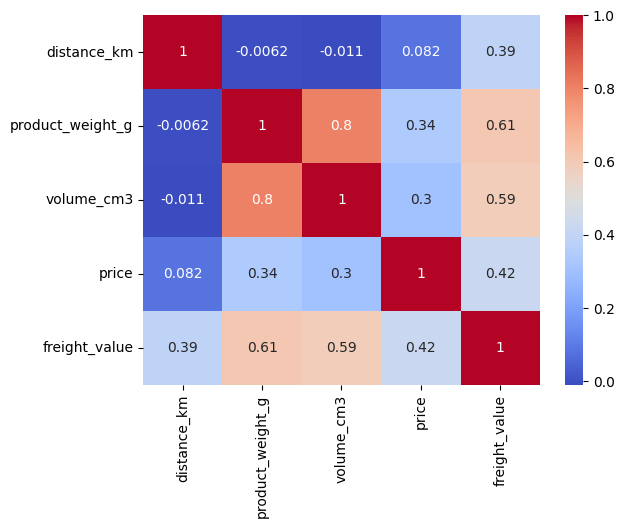

In [46]:

sns.heatmap(df[num_cols].corr(),cmap='coolwarm',annot=True)
plt.show()

In [47]:
### preparing ml pipeline

In [48]:
from sklearn.model_selection import train_test_split

from sklearn.preprocessing import RobustScaler,OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer

from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor,GradientBoostingRegressor
from xgboost import XGBRegressor

from sklearn.metrics import *

In [49]:
x=df.iloc[:,:-1]
y=df['freight_value']
x.columns

Index(['seller_state', 'customer_state', 'distance_km', 'product_weight_g',
       'volume_cm3', 'price'],
      dtype='object')

In [50]:
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.3,random_state=42)
x_train.shape,x_test.shape,y_train.shape,y_test.shape

((70884, 6), (30379, 6), (70884,), (30379,))

In [51]:
num_cols=x.dtypes[x.dtypes!='object'].index
cat_cols=x.dtypes[x.dtypes=='object'].index

In [52]:
cat_pipeline=Pipeline([
    ('encoding',OneHotEncoder(drop='first'))])
num_pipeline=Pipeline([
    ('Rscaler',RobustScaler(quantile_range=(5.0, 95.0)))])

In [53]:
preprocessor=ColumnTransformer([
    ('num_cols',num_pipeline,num_cols),
    ('cat_cols',cat_pipeline,cat_cols)
])

In [53]:
def eval(x_train,y_train,x_test,y_test,model,model_name):
    model.fit(x_train,y_train)
    y_pred=model.predict(x_test)
    r2=model.score(x_test,y_test)
    mse=mean_squared_error(y_test,y_pred)
    mae=mean_absolute_error(y_test,y_pred)
    rmse=np.sqrt(mse)
    e_df=pd.DataFrame({
        'Model': [model_name],
        'R2 Score': [r2],
        'MSE': [mse],
        'RMSE': [rmse],
        'MAE': [mae]
    })
    return e_df

In [54]:
lr_pipeline=Pipeline([
    ('preprocessing',preprocessor),
    ('model',LinearRegression(n_jobs=-1))])
lr_eval=eval(x_train,y_train,x_test,y_test,lr_pipeline,'LR')

# 0	LR	0.561406	75.615183	8.695699	4.720046

In [55]:
lr_eval

,Model,R2 Score,MSE,RMSE,MAE
0,LR,0.608449,100.384141,10.019189,5.209405


In [56]:
rf_pipeline=Pipeline([
    ('preprocessing',preprocessor),
    ('model',RandomForestRegressor(max_depth=5,criterion='squared_error',min_samples_split=15,verbose=1,n_jobs=-1))])
rf_eval=eval(x_train,y_train,x_test,y_test,rf_pipeline,'RF')

[Parallel(n_jobs=-1)]: Using backend ThreadingBackend with 24 concurrent workers.
[Parallel(n_jobs=-1)]: Done   2 tasks      | elapsed:    0.0s
[Parallel(n_jobs=-1)]: Done 100 out of 100 | elapsed:    0.4s finished
[Parallel(n_jobs=24)]: Using backend ThreadingBackend with 24 concurrent workers.
[Parallel(n_jobs=24)]: Done   2 tasks      | elapsed:    0.0s
[Parallel(n_jobs=24)]: Done 100 out of 100 | elapsed:    0.0s finished
[Parallel(n_jobs=24)]: Using backend ThreadingBackend with 24 concurrent workers.
[Parallel(n_jobs=24)]: Done   2 tasks      | elapsed:    0.0s
[Parallel(n_jobs=24)]: Done 100 out of 100 | elapsed:    0.0s finished


In [57]:
rf_eval
# 0	RF	0.571743	73.833144	8.592621	4.524199
# RF	0.640366	92.201269	9.602149	4.785666


,Model,R2 Score,MSE,RMSE,MAE
0,RF,0.641048,92.02641,9.59304,4.793993


In [58]:
gb_pipeline=Pipeline([
    ('preprocessing',preprocessor),
    ('model',GradientBoostingRegressor(n_estimators=150,max_depth=7,min_samples_split=10,verbose=1))])
gb_eval=eval(x_train,y_train,x_test,y_test,gb_pipeline,'GB')
gb_eval
# 0	GB	0.723488	70.890991	8.419679	3.839928


      Iter       Train Loss   Remaining Time 
         1         218.8195           26.94s
         2         191.2115           25.54s
         3         168.4197           25.50s
         4         149.5798           26.02s
         5         134.2104           25.93s
         6         121.4082           25.92s
         7         110.7030           25.80s
         8         101.7269           25.70s
         9          94.3263           25.55s
        10          88.2376           25.51s
        20          60.3794           23.59s
        30          52.7419           21.01s
        40          49.2007           18.40s
        50          47.1459           16.17s
        60          45.6294           14.19s
        70          44.6225           12.38s
        80          43.5877           10.71s
        90          42.6879            9.07s
       100          41.8003            7.52s


,Model,R2 Score,MSE,RMSE,MAE
0,GB,0.723701,70.836338,8.416433,3.839731


In [59]:
xg_pipeline=Pipeline([
    ('preprocessing',preprocessor),
    ('model',XGBRegressor(n_estimators=150,max_depth=7,n_jobs=-1))])
xg_eval=eval(x_train,y_train,x_test,y_test,xg_pipeline,'XG')
xg_eval
# 0	XG	0.660205	58.581898	7.653881	3.62205
# 	XG	0.725948	70.260312	8.382142	3.805367

,Model,R2 Score,MSE,RMSE,MAE
0,XG,0.725948,70.260312,8.382142,3.805367


In [63]:
from sklearn.model_selection import GridSearchCV

In [112]:
pipe = Pipeline([
    ('prepr', preprocessor),
    ('rf', RandomForestRegressor(random_state=42))
])

In [113]:
param_grid = {
    'rf__n_estimators': [85,100,150,200],
    'rf__max_depth': [None, 5,7 ,10, 20],
    'rf__min_samples_split': [5, 10, 15],        
    'rf__min_samples_leaf': [2, 4, 6],          
    'rf__max_features': [None , 'sqrt', 'log2'],
    'rf__bootstrap': [True, False]
}
gs_rf=GridSearchCV(estimator=pipe,param_grid=param_grid,cv=5,scoring='r2',n_jobs=-1,verbose=1)
gs_rf.fit(x_train, y_train)
  
print("Best params:", gs_rf.best_params_)
print("Best score:", gs_rf.best_score_)
# Best params: {'rf__bootstrap': False, 'rf__max_depth': None, 'rf__max_features': 'sqrt', 'rf__min_samples_leaf': 2, 'rf__min_samples_split': 15, 'rf__n_estimators': 150}
# Best score: 0.6151499082699152

Fitting 5 folds for each of 1080 candidates, totalling 5400 fits
Best params: {'rf__bootstrap': True, 'rf__max_depth': 20, 'rf__max_features': None, 'rf__min_samples_leaf': 2, 'rf__min_samples_split': 5, 'rf__n_estimators': 200}
Best score: 0.7278301501752644


In [120]:
pipe = Pipeline([
    ('prepr', preprocessor),
    ('rf1', RandomForestRegressor(random_state=42))
])
param_grid = {
    'rf1__n_estimators': [85,100,150,200],
    'rf1__max_depth': [5,7 ,10, 20],
    'rf1__min_samples_split': [5, 10, 15,20],        
    'rf1__min_samples_leaf': [2, 6,10],
    'rf1__bootstrap': [True, False]
}
gs_rf1=GridSearchCV(estimator=pipe,param_grid=param_grid,cv=5,scoring='r2',n_jobs=-1,verbose=1)
gs_rf1.fit(x_train, y_train)
  
print("Best params:", gs_rf1.best_params_)
print("Best score:", gs_rf1.best_score_)

Fitting 5 folds for each of 384 candidates, totalling 1920 fits
Best params: {'rf1__bootstrap': True, 'rf1__max_depth': 20, 'rf1__min_samples_leaf': 2, 'rf1__min_samples_split': 5, 'rf1__n_estimators': 200}
Best score: 0.7278301501752644


In [114]:
x2=pd.DataFrame(gs_rf.cv_results_)
x2

,mean_fit_time,std_fit_time,mean_score_time,std_score_time,param_rf__bootstrap,param_rf__max_depth,param_rf__max_features,param_rf__min_samples_leaf,param_rf__min_samples_split,param_rf__n_estimators,params,split0_test_score,split1_test_score,split2_test_score,split3_test_score,split4_test_score,mean_test_score,std_test_score,rank_test_score
0,133.837950,4.645486,0.266694,0.046095,True,None,None,2,5,85,"{'rf__bootstrap': True, 'rf__max_depth': None,...",0.717174,0.718248,0.733566,0.724280,0.735764,0.725806,0.007660,15
1,161.284176,4.905951,0.363018,0.061842,True,None,None,2,5,100,"{'rf__bootstrap': True, 'rf__max_depth': None,...",0.716587,0.718513,0.734696,0.725888,0.736069,0.726350,0.008013,10
2,248.151412,4.335091,0.461243,0.013737,True,None,None,2,5,150,"{'rf__bootstrap': True, 'rf__max_depth': None,...",0.719309,0.718663,0.735385,0.726633,0.736004,0.727199,0.007483,5
3,332.732347,2.743048,0.643332,0.016206,True,None,None,2,5,200,"{'rf__bootstrap': True, 'rf__max_depth': None,...",0.719160,0.719373,0.735464,0.728237,0.736563,0.727759,0.007502,2
4,107.696150,4.123049,0.282302,0.064877,True,None,None,2,10,85,"{'rf__bootstrap': True, 'rf__max_depth': None,...",0.714265,0.718687,0.732707,0.726604,0.737240,0.725900,0.008519,14
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1075,41.129116,1.023775,0.230817,0.022859,False,20,log2,6,10,200,"{'rf__bootstrap': False, 'rf__max_depth': 20, ...",0.673787,0.688128,0.663528,0.669416,0.698555,0.678683,0.012835,395
1076,15.764070,0.719186,0.132023,0.018861,False,20,log2,6,15,85,"{'rf__bootstrap': False, 'rf__max_depth': 20, ...",0.676973,0.687533,0.663695,0.668857,0.700103,0.679432,0.013103,391
1077,22.147663,0.689412,0.155675,0.032197,False,20,log2,6,15,100,"{'rf__bootstrap': False, 'rf__max_depth': 20, ...",0.677317,0.686991,0.662898,0.670075,0.701227,0.679702,0.013395,390
1078,30.124151,0.794153,0.167594,0.002809,False,20,log2,6,15,150,"{'rf__bootstrap': False, 'rf__max_depth': 20, ...",0.677303,0.687889,0.663709,0.670828,0.700128,0.679971,0.012839,389


In [121]:
pipe = Pipeline([
    ('prepr', preprocessor),
    ('gb', GradientBoostingRegressor(random_state=42))
])
param_grid = {
    'gb__n_estimators': [100, 150, 200],
    'gb__max_depth': [5, 7,10],
    'gb__min_samples_split': [20, 5, 10],
    'gb__min_samples_leaf': [2, 4, 10, 20]
}

gs_gb=GridSearchCV(estimator=pipe,param_grid=param_grid,cv=5,scoring='r2',n_jobs=-1,verbose=1)
gs_gb.fit(x_train, y_train)

print("Best params:", gs_gb.best_params_)
print("Best score:", gs_gb.best_score_)
# Best params: {'gb__learning_rate': 0.1, 'gb__max_depth': 10, 'gb__max_features': 'sqrt', 'gb__min_samples_leaf': 4, 'gb__min_samples_split': 10, 'gb__n_estimators': 200, 'gb__subsample': 1.0}
# Best score: 0.6378972915025621


# Best params: {'gb__learning_rate': 0.1, 'gb__max_depth': 10, 'gb__max_features': 'sqrt', 'gb__min_samples_leaf': 4, 'gb__min_samples_split': 5, 'gb__n_estimators': 200, 'gb__subsample': 1.0}
# Best score: 0.6827905313818349
# Best params: {'gb__learning_rate': 0.05, 'gb__max_depth': 10, 'gb__max_features': None, 'gb__min_samples_leaf': 4, 'gb__min_samples_split': 10, 'gb__n_estimators': 200, 'gb__subsample': 0.8}
# Best score: 0.7302586372648788

Fitting 5 folds for each of 108 candidates, totalling 540 fits
Best params: {'gb__max_depth': 7, 'gb__min_samples_leaf': 4, 'gb__min_samples_split': 5, 'gb__n_estimators': 200}
Best score: 0.7286447197572042


In [70]:
pipe = Pipeline([
    ('prepr', preprocessor),
    ('xgb', XGBRegressor(random_state=42))
])
param_grid = {
    'xgb__n_estimators': [100, 150,200, 300],
    'xgb__max_depth': [5, 7,10],
    'xgb__learning_rate': [0.01, 0.05, 0.1,0.15,0.3]
}


gs_xgb=GridSearchCV(estimator=pipe,param_grid=param_grid,cv=5,scoring='r2',n_jobs=-1,verbose=1)
gs_xgb.fit(x_train, y_train)

print("Best params:", gs_xgb.best_params_)
print("Best score:", gs_xgb.best_score_)
# Best params: {'xgb__learning_rate': 0.1, 'xgb__max_depth': 7, 'xgb__n_estimators': 300}
# Best score: 0.6198589856100378

# Best params: {'xgb__learning_rate': 0.1, 'xgb__max_depth': 7, 'xgb__n_estimators': 300}
# Best score: 0.6681407029274791

Fitting 5 folds for each of 60 candidates, totalling 300 fits
Best params: {'xgb__learning_rate': 0.1, 'xgb__max_depth': 7, 'xgb__n_estimators': 300}
Best score: 0.7136758227522305


## hyperparameter tunned model evaluations

In [71]:
ht_rf_pipeline=Pipeline([
    ('preprocessing',preprocessor),
    ('model',RandomForestRegressor(bootstrap= True, max_depth= 20, min_samples_leaf= 2, min_samples_split= 5, n_estimators= 200,n_jobs=-1))])
ht_rf_eval=eval(x_train,y_train,x_test,y_test,ht_rf_pipeline,'Tunned_RF')

In [72]:
ht_rf_eval

,Model,R2 Score,MSE,RMSE,MAE
0,Tunned_RF,0.72786,69.770008,8.352844,3.713425


In [73]:
ht_gb_pipeline=Pipeline([
    ('preprocessing',preprocessor),
    ('model',GradientBoostingRegressor(max_depth= 7, min_samples_leaf= 4, min_samples_split= 5, n_estimators= 200))])
ht_gb_eval=eval(x_train,y_train,x_test,y_test,ht_gb_pipeline,'Tunned_gb')
ht_gb_eval

,Model,R2 Score,MSE,RMSE,MAE
0,Tunned_gb,0.733842,68.236489,8.260538,3.771138


In [74]:
ht_xgb_pipeline=Pipeline([
    ('preprocessing',preprocessor),
    ('model',XGBRegressor(learning_rate= 0.1, max_depth= 7, n_estimators= 300))])
ht_xgb_eval=eval(x_train,y_train,x_test,y_test,ht_xgb_pipeline,'Tunned_xgb')
ht_xgb_eval

,Model,R2 Score,MSE,RMSE,MAE
0,Tunned_xgb,0.729406,69.373706,8.329088,3.772686


In [75]:
tunned_eval_df=pd.concat([ht_rf_eval,ht_gb_eval,ht_xgb_eval])
tunned_eval_df

,Model,R2 Score,MSE,RMSE,MAE
0,Tunned_RF,0.727860,69.770008,8.352844,3.713425
0,Tunned_gb,0.733842,68.236489,8.260538,3.771138
0,Tunned_xgb,0.729406,69.373706,8.329088,3.772686


### saving the model

In [76]:
import joblib

In [77]:
joblib.dump(ht_rf_pipeline, "rf_pipeline.pkl")
joblib.dump(ht_gb_pipeline, "gb_pipeline.pkl")
joblib.dump(ht_xgb_pipeline, "xgb_pipeline.pkl")

['xgb_pipeline.pkl']

In [78]:
tunned_eval_df.to_csv('tunned_model_evaluations.csv',index=False)

In [58]:
x['customer_state'].unique()

array(['RJ', 'SP', 'MG', 'PR', 'GO', 'BA', 'AL', 'MS', 'CE', 'DF', 'RS',
       'PE', 'SC', 'ES', 'MA', 'PA', 'MT', 'PB', 'AM', 'AP', 'PI', 'TO',
       'RO', 'RN', 'SE', 'AC', 'RR'], dtype=object)

In [59]:
df['customer_state'].unique()

array(['RJ', 'SP', 'MG', 'PR', 'GO', 'BA', 'AL', 'MS', 'CE', 'DF', 'RS',
       'PE', 'SC', 'ES', 'MA', 'PA', 'MT', 'PB', 'AM', 'AP', 'PI', 'TO',
       'RO', 'RN', 'SE', 'AC', 'RR'], dtype=object)

In [62]:
### getting al versions

In [61]:
import streamlit, pandas, sklearn, matplotlib, numpy, seaborn, plotly

print("streamlit==", streamlit.__version__)
print("pandas==", pandas.__version__)
print("scikit-learn==", sklearn.__version__)
print("matplotlib==", matplotlib.__version__)
print("numpy==", numpy.__version__)
print("seaborn==", seaborn.__version__)
print("plotly==", plotly.__version__)

streamlit== 1.57.0
pandas== 2.3.3
scikit-learn== 1.9.0
matplotlib== 3.10.9
numpy== 2.3.5
seaborn== 0.13.2
plotly== 6.3.0
